In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("OnlineRetail.csv", encoding="ISO-8859-1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [15]:

import pandas as pd

file_path = r"C:\Users\srish\Retail_Sales_Analysis_Project\OnlineRetail.csv\OnlineRetail.csv"

df = pd.read_csv(file_path, encoding="ISO-8859-1")

print("✅ Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())






✅ Dataset loaded successfully!
Number of rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [16]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())



Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [17]:

# 1. Display dataset size
print("Dataset Shape:", df.shape)

# 2. Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Check data types and non-null values
print("\nDataset Information:")
df.info()

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 6. Display summary statistics
print("\nSummary Statistics:")
display(df.describe())





Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 526

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [18]:

# Calculate revenue for each transaction line
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Display total revenue
total_revenue = df["Revenue"].sum()

print(f"Total Sales Revenue: £{total_revenue:,.2f}")



Total Sales Revenue: £9,747,747.93


In [19]:

# Create a copy so the original dataset remains unchanged
df_clean = df.copy()

# 1. Check missing values
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# 2. Check duplicate rows
print("\nDuplicate rows before cleaning:")
print(df_clean.duplicated().sum())

# 3. Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# 4. Remove rows with missing product descriptions
df_clean = df_clean.dropna(subset=["Description"])

# 5. Remove invalid quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# 6. Calculate revenue on the cleaned data
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("\nCleaning completed!")
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Missing values after cleaning:")
print(df_clean.isnull().sum())



Missing values before cleaning:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Revenue             0
dtype: int64

Duplicate rows before cleaning:
5268

Cleaning completed!
Original dataset shape: (541909, 9)
Cleaned dataset shape: (524878, 9)
Missing values after cleaning:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
dtype: int64


In [20]:

# Find the top 10 products by quantity sold
top_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Best-Selling Products:")
display(top_products)



Top 10 Best-Selling Products:


Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

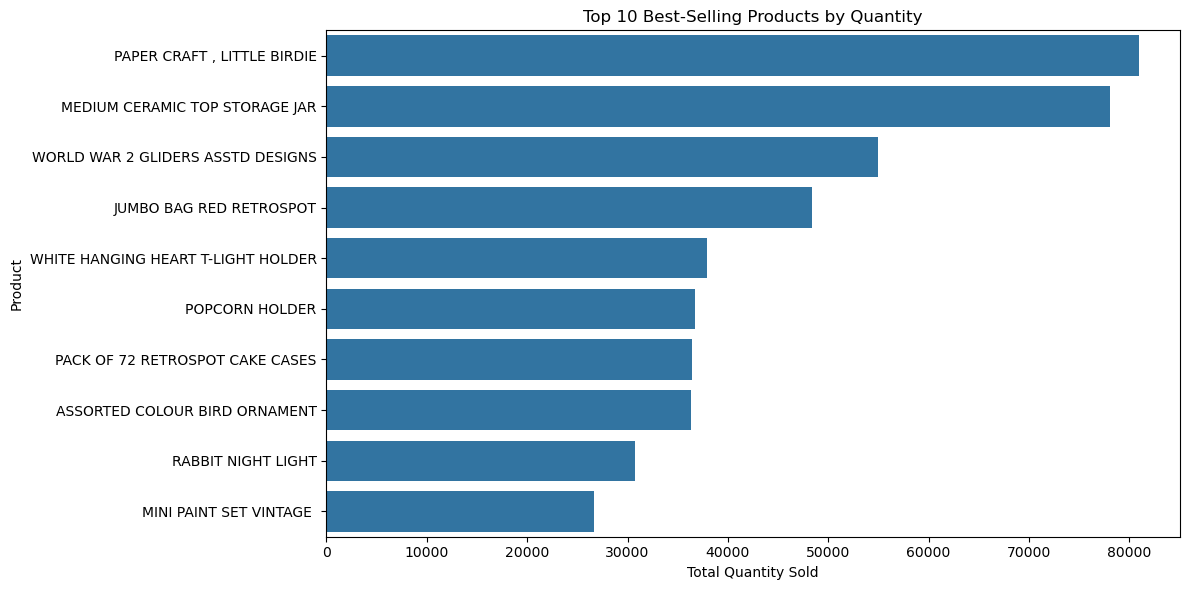

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Best-Selling Products by Quantity")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig("top_10_best_selling_products.png", dpi=300)
plt.show()

In [22]:

# Convert InvoiceDate to datetime format
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Remove rows with invalid invoice dates
df_clean = df_clean.dropna(subset=["InvoiceDate"]).copy()

# Extract month and year
df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = (
    df_clean.groupby("Month")["Revenue"]
    .sum()
    .sort_index()
)

print("Monthly Sales Revenue:")
display(monthly_sales)



Monthly Sales Revenue:


Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64

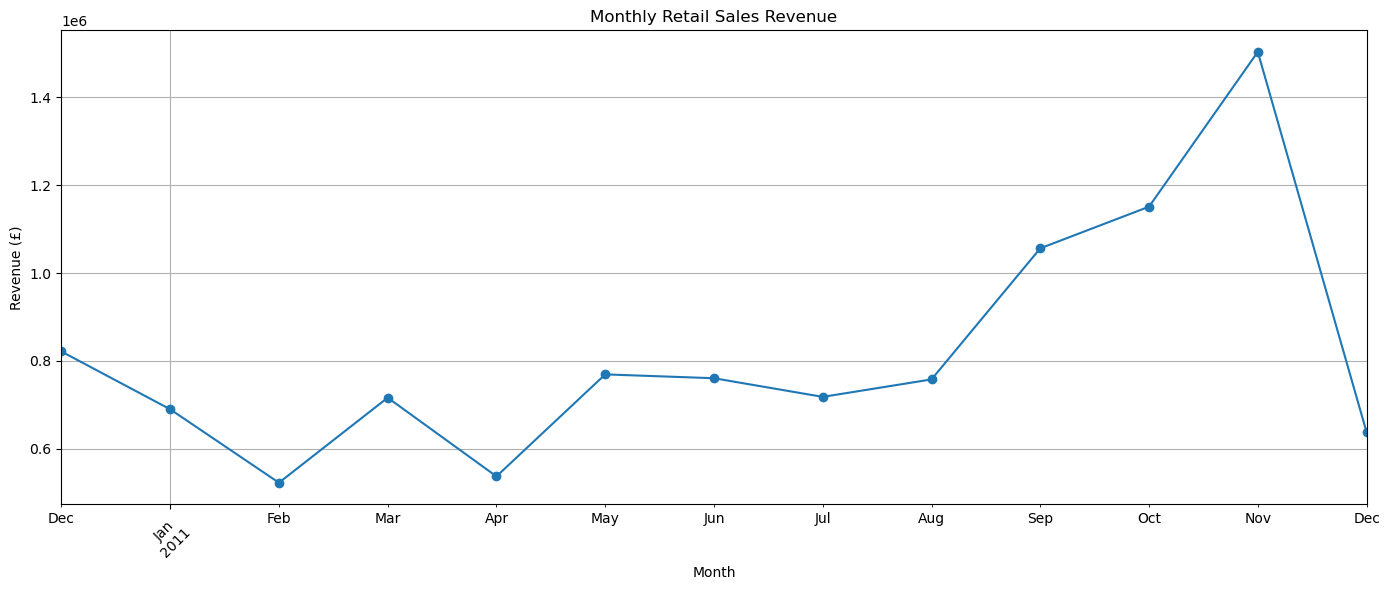

In [23]:

plt.figure(figsize=(14, 6))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Retail Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig("monthly_sales_trend.png", dpi=300)
plt.show()



In [24]:

# Calculate revenue by country
country_sales = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Revenue:")
display(country_sales.head(10))



Top 10 Countries by Revenue:


Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

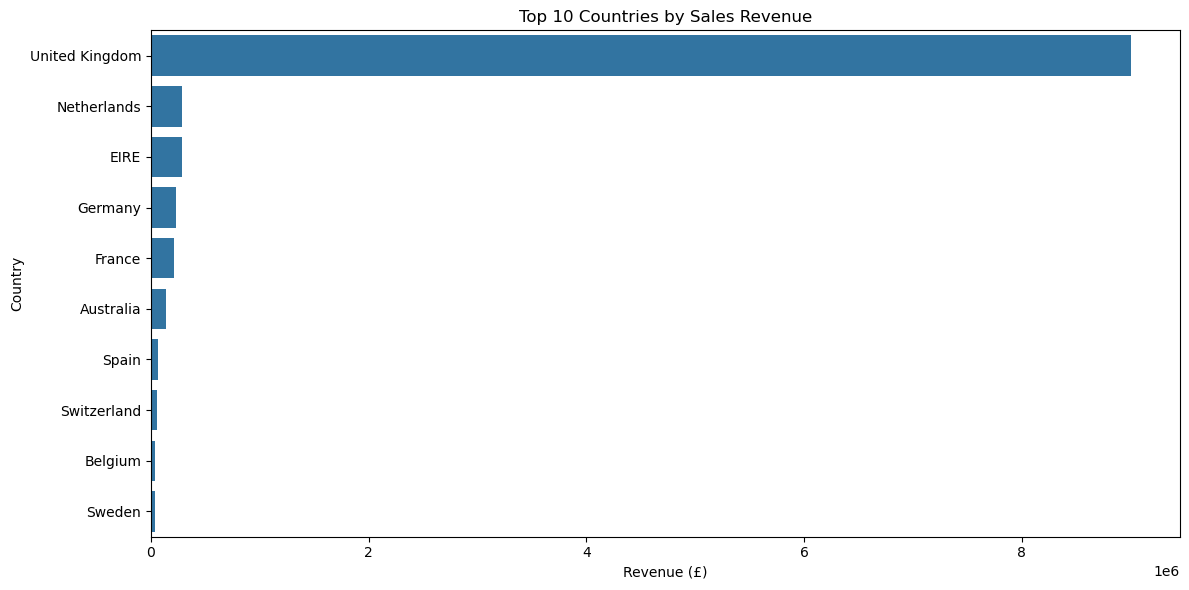

In [25]:
top_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig("top_10_countries_by_revenue.png", dpi=300)
plt.show()

In [26]:
print("===== RETAIL BUSINESS INSIGHTS =====")

print(
    "\n1. Highest Revenue Month:",
    monthly_sales.idxmax(),
    f"(£{monthly_sales.max():,.2f})"
)

print(
    "\n2. Highest Revenue Country:",
    country_sales.idxmax(),
    f"(£{country_sales.max():,.2f})"
)

print(
    "\n3. Highest Quantity-Selling Product:",
    top_products.index[0],
    f"({top_products.iloc[0]:,} units)"
)

print(
    "\n4. Total Revenue in Cleaned Dataset:",
    f"£{df_clean['Revenue'].sum():,.2f}"
)

===== RETAIL BUSINESS INSIGHTS =====

1. Highest Revenue Month: 2011-11 (£1,503,866.78)

2. Highest Revenue Country: United Kingdom (£9,001,744.09)

3. Highest Quantity-Selling Product: PAPER CRAFT , LITTLE BIRDIE (80,995 units)

4. Total Revenue in Cleaned Dataset: £10,642,110.80
